# Lab 5 – Spatial Filtering: Smoothing and Sharpening

In [1]:
import os
import cv2
import requests
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

os.makedirs('images', exist_ok=True)

def get_img(url):
    resp = requests.get(url)
    return cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_GRAYSCALE)

def show_side_by_side(images, titles, cmap=None):
    fig, ax = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for a, im, t in zip(ax, images, titles):
        a.imshow(im, cmap=cmap); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

## Task#1: Unsharp Masking

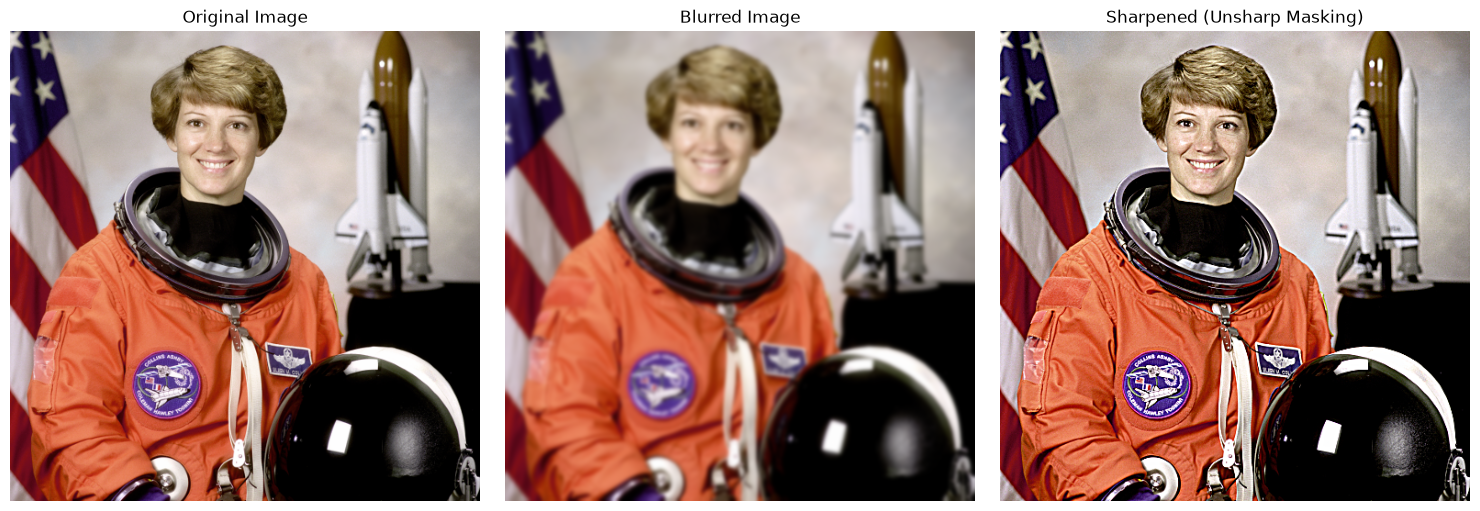

In [2]:
# Read the image (color, RGB)
image = data.astronaut()
cv2.imwrite('images/astronaut.png', cv2.cvtColor(image, cv2.COLOR_RGB2BGR))

# Gaussian sigma
sigma = 2

# parameter
amount = 1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

show_side_by_side([image, blurred, sharpened],
                  ['Original Image', 'Blurred Image', 'Sharpened (Unsharp Masking)'])

# Assessment

### Task#1: Convolve an image with a 7x7 box filter

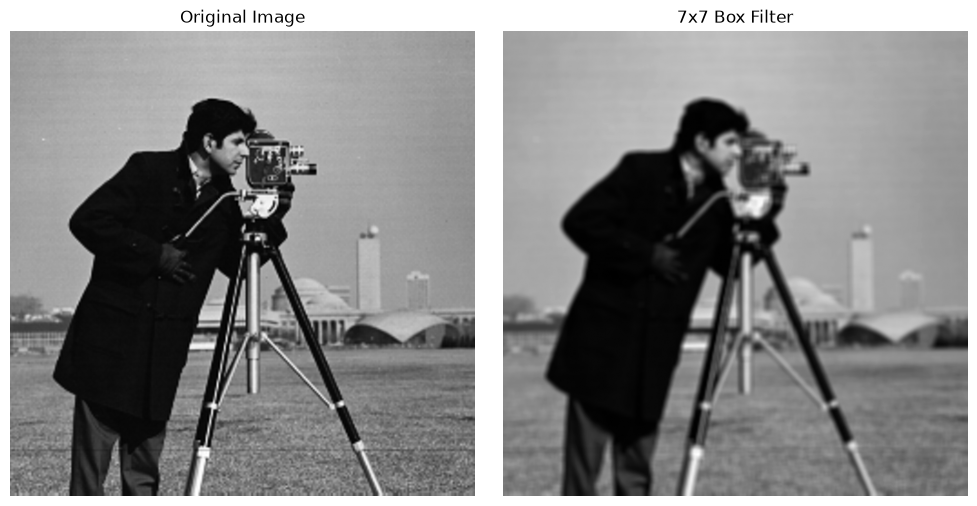

In [3]:
img = get_img("https://raw.githubusercontent.com/ashish-kmr/BTP_inpaint/master/cameraman.tif")
cv2.imwrite('images/cameraman.png', img)

kernel = np.ones((7, 7), np.float32) / 49
box = cv2.filter2D(img, -1, kernel)

show_side_by_side([img, box], ['Original Image', '7x7 Box Filter'], cmap='gray')

### Task#2: 5x5 and 21x21 Gaussian filters

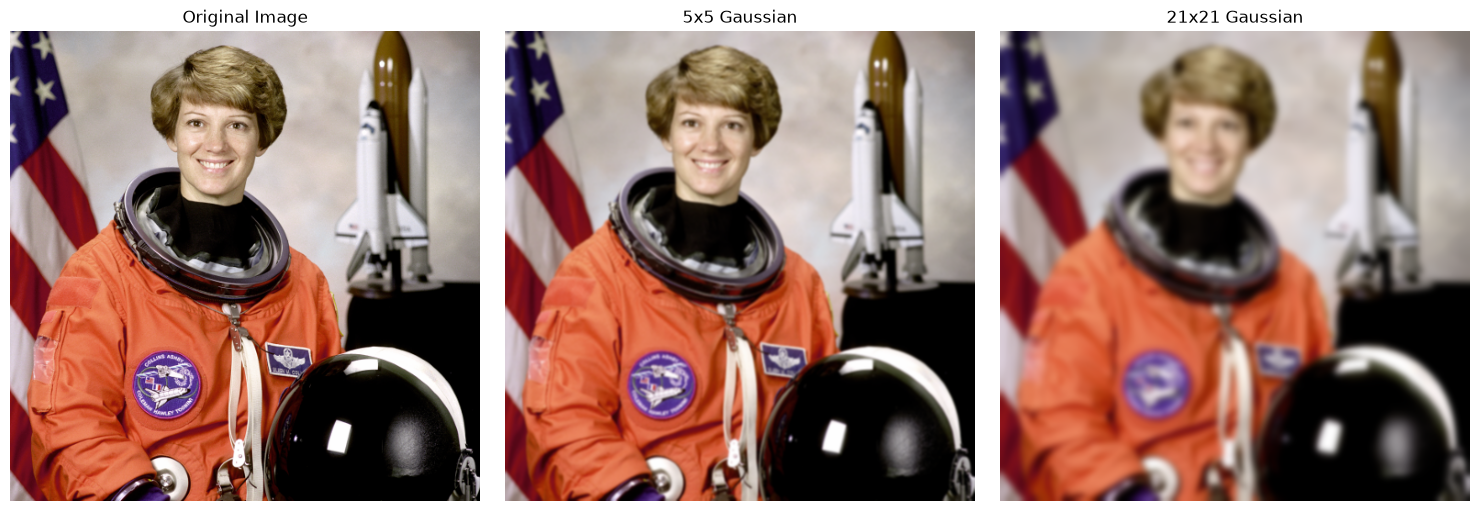

In [4]:
gauss5 = cv2.GaussianBlur(image, (5, 5), 0)
gauss21 = cv2.GaussianBlur(image, (21, 21), 0)

show_side_by_side([image, gauss5, gauss21], ['Original Image', '5x5 Gaussian', '21x21 Gaussian'])

### Task#3: Sharpening with a 3x3 Laplacian filter

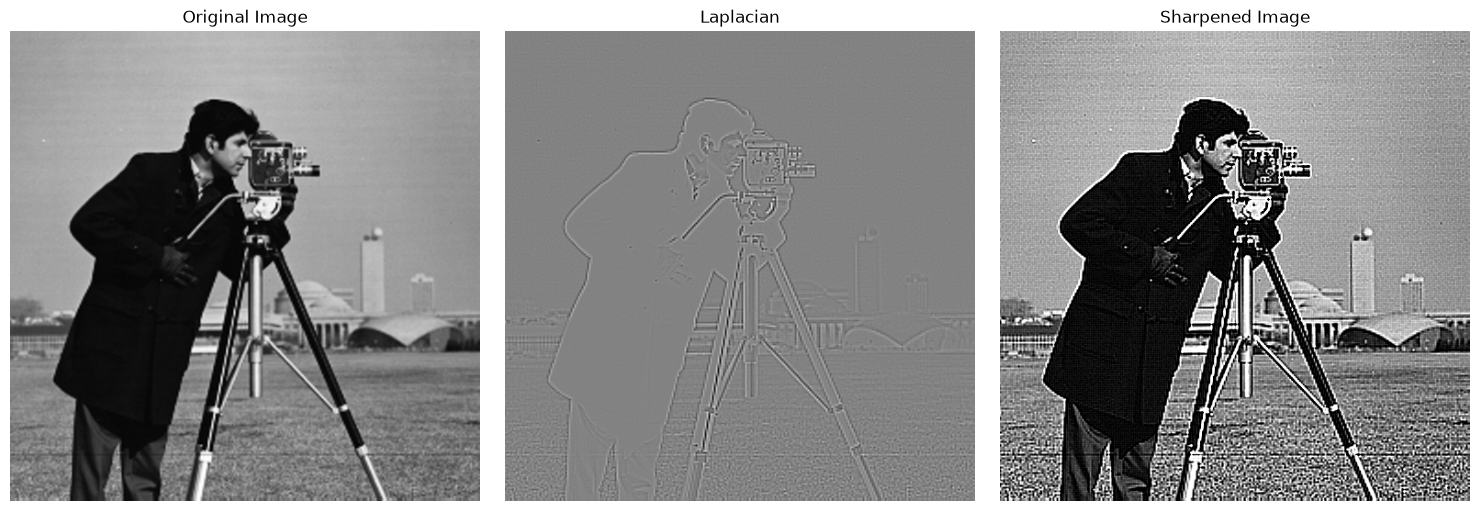

In [5]:
# Read the image
img = get_img("https://raw.githubusercontent.com/ashish-kmr/BTP_inpaint/master/cameraman.tif")

# Convert image to float32
image_float = img.astype(np.float32) / 255.0

# Laplacian (3x3 kernel)
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

# Sharpen
sharpened = np.clip(image_float - laplacian, 0, 1)

show_side_by_side([image_float, laplacian, sharpened],
                  ['Original Image', 'Laplacian', 'Sharpened Image'], cmap='gray')